# playerCorrelations: how linked are players' fantasy points, and does it decide matchups?

**Hypothesis:** fantasy points are correlated between players in the **same NFL game**:
- **Teammates** at different positions (a QB and his receivers rise and fall together).
- **Opponents** (a shootout lifts both offenses; a D/ST does well when the offense it faces does badly).
- **Kickers and D/STs** with the offenses around them.

Players in **different NFL games** are assumed independent (correlation 0). Section 3 checks that.

**Why it matters for a matchup.** A matchup is decided by the margin M = A − B:

$$\operatorname{Var}(M) = \operatorname{Var}(A) + \operatorname{Var}(B) - 2\,\operatorname{Cov}(A, B)$$

- Var(A) is the sum of each starter's variance **plus** 2·Cov for every correlated pair on the
  same roster. A stack makes a team's score swingier.
- Cov(A, B) comes from pairs split across the two rosters in the same NFL game. A positive
  correlation there links the two scores and makes the margin *less* variable.
- Correlation never changes **expected** points, only the spread. Its effect on results is
  through win probability: more variance helps the underdog.

**Scope:** 2026 only, so players are on this season's teams. Each record carries that week's
NFL team, so mid-season trades are handled. Completed fantasy weeks only.

1. **Player-weeks:** points and a baseline for each player.
2. **Correlations** by position, for teammates, opponents and players in different games.
3. **The independence check:** players in different games.
4. **Exposure:** how many correlated pairs this league's lineups actually carry.
5. **Impact:** team-score spread, margin spread and win probability, with and without correlation.
6. **A week up close:** real matchups, their lineups and every correlated pair.
7. **How big can it get:** hypothetical stacks.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm

from fantasy_analysis.application.frames import (
    lineup_entries_frame,
    nfl_team_stats_frame,
    player_stats_frame,
)
from fantasy_analysis.application.nfl_stats import attach_player_stats, attach_team_stats
from fantasy_analysis.config import settings
from fantasy_analysis.infrastructure.espn import EspnLeagueRepository
from fantasy_analysis.infrastructure.nflverse import (
    NflversePlayerStatsRepository,
    NflverseTeamStatsRepository,
)

pd.set_option("display.max_columns", 50)

SEASON = 2026

## Chart style

In [3]:
COLORS = {
    "surface": "#fcfcfb",
    "primary": "#0b0b0b",
    "secondary": "#52514e",
    "muted": "#898781",
    "grid": "#e1e0d9",
    "axis": "#c3c2b7",
    "neutral": "#f0efec",  # diverging midpoint
    "same": "#2a78d6",  # categorical 1, blue: teammates
    "opp": "#eb6834",  # categorical 2, orange: opponents in the same game
    "series": "#2a78d6",
}
# Diverging: red (negative) -> gray (0) -> blue (positive)
DIVERGING = LinearSegmentedColormap.from_list(
    "corr", ["#a52a2a", "#e34948", COLORS["neutral"], "#2a78d6", "#184f95"]
)

plt.rcParams.update(
    {
        "figure.facecolor": COLORS["surface"],
        "axes.facecolor": COLORS["surface"],
        "savefig.facecolor": COLORS["surface"],
        "text.color": COLORS["primary"],
        "axes.labelcolor": COLORS["secondary"],
        "axes.edgecolor": COLORS["axis"],
        "xtick.color": COLORS["muted"],
        "ytick.color": COLORS["muted"],
        "axes.grid": True,
        "grid.color": COLORS["grid"],
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    }
)

## Load the season

In [4]:
league = EspnLeagueRepository.from_settings(settings).get_league(SEASON)
attach_player_stats(league, NflversePlayerStatsRepository())
attach_team_stats(league, NflverseTeamStatsRepository())

OWNERS = {t.name: t.owner.split()[0].capitalize() for t in league.teams}
OWNERS["The Germiphobes"] = "Kinch"
OWNERS["Chase You to the Playoffs"] = "Levitt"
OWNERS["#EATITFROMTHEBACK"] = "Stein"


def with_owner(team: str, sep: str = " · ") -> str:
    return f"{team}{sep}{OWNERS[team]}"


entries = lineup_entries_frame(league)
LAST_WEEK = int(entries["week"].max())  # last completed fantasy week
stats = player_stats_frame(league)
team_stats = nfl_team_stats_frame(league)
# (NFL team, week) -> opponent that week. No entry on a bye.
OPPONENT = team_stats.set_index(["team", "week"])["opponent"].to_dict()

print(f"{league.name} {SEASON}: weeks 1-{LAST_WEEK}")

The Corrupt League 2026: weeks 1-7


## 1. Player-weeks

**Population.** Every player who was on a fantasy roster at any point in 2026.
- **QB / RB / WR / TE:** nflverse half-PPR points for *every* week they played, rostered or
  not. That matches ESPN exactly this season, and it gives far more weeks than lineups alone.
- **K / D/ST:** ESPN's lineup points, so only weeks when someone rostered them (starting or
  benched). nflverse doesn't score kicking or D/STs.

**Baseline.** Good QBs throw to good receivers, so correlating raw points would mostly measure
*talent*. We correlate *surprises* instead: each week's points minus the player's
**leave-one-out** average (his average in his other weeks). Players need at least 3 weeks.

**Positions only.** Players are compared by position (QB, RB, WR, TE, K, D/ST), not by depth
order. Fantasy points don't give a real depth chart, so "WR1 vs. WR2" would be guesswork.

In [5]:
skill = stats.loc[stats["position"].isin(["QB", "RB", "WR", "TE"]) & (stats["week"] <= LAST_WEEK)]
skill = skill.assign(points=skill["half_ppr_points"])[
    ["player_id", "player", "position", "week", "team", "opponent", "points"]
]

# K and D/ST: ESPN points for weeks they were rostered. A player is on one roster per week.
kdst = entries.loc[entries["position"].isin(["K", "DST"])].drop_duplicates(["player_id", "week"])
kdst = kdst.drop(columns="team").rename(columns={"pro_team": "team"})
kdst = kdst[["player_id", "player", "position", "week", "team", "points"]].copy()
kdst["opponent"] = [OPPONENT.get(tw) for tw in zip(kdst["team"], kdst["week"], strict=True)]
kdst = kdst.dropna(subset=["opponent"])  # rostered on a bye

obs = pd.concat([skill, kdst], ignore_index=True)

by_player = obs.groupby("player_id")["points"]
n_weeks = by_player.transform("count")
obs["loo_mean"] = (by_player.transform("sum") - obs["points"]) / (n_weeks - 1)
obs = obs.loc[n_weeks >= 3].copy()
obs["resid"] = obs["points"] - obs["loo_mean"]

POSITIONS = ["QB", "RB", "WR", "TE", "K", "DST"]

summary = obs.groupby("position").agg(
    player_weeks=("points", "size"),
    players=("player_id", "nunique"),
    avg_points=("points", "mean"),
    sd_surprise=("resid", "std"),
)
summary.loc[POSITIONS].round(1)

,player_weeks,players,avg_points,sd_surprise
position,,,,
QB,144,24,17.8,8.3
RB,354,61,10.4,7.1
WR,449,76,9.5,7.2
TE,163,26,8.7,7.0
K,59,12,9.9,6.1
DST,61,13,7.0,6.6


## 2. Correlations by position

Every pair of player-weeks in the same week falls into one of three groups:
- **Teammates:** same NFL team.
- **Opponents:** the two NFL teams playing each other.
- **Different games:** everything else. Should be 0.

For each pair of positions, the correlation of their surprises. Same-position cells count
pairs of different players (e.g. two WRs on one team). Cells with fewer than 15 pairs are
left blank. With ~100 pairs a correlation is uncertain by about ±0.2. These values are what
the matchup model in section 5 uses.

In [6]:
COLS = ["player_id", "week", "team", "opponent", "position", "resid"]
pw = obs[COLS]

teammates = pw.merge(pw, on=["week", "team"], suffixes=("_a", "_b"))
teammates = teammates.loc[teammates["player_id_a"] < teammates["player_id_b"]]

opponents = pw.merge(
    pw, left_on=["week", "opponent"], right_on=["week", "team"], suffixes=("_a", "_b")
)
opponents = opponents.loc[opponents["player_id_a"] < opponents["player_id_b"]]

other_games = pw.merge(pw, on="week", suffixes=("_a", "_b"))
other_games = other_games.loc[
    (other_games["player_id_a"] < other_games["player_id_b"])
    & (other_games["team_a"] != other_games["team_b"])
    & (other_games["team_a"] != other_games["opponent_b"])
]
RELATIONS = {"Teammates": teammates, "Opponents": opponents, "Different games": other_games}
print({k: len(v) for k, v in RELATIONS.items()})


def ordered(pairs: pd.DataFrame, key: str, order: list[str]) -> pd.DataFrame:
    # Each pair as (lower-ordered label, higher-ordered label, its surprise, the other's)
    a, b = pairs[f"{key}_a"], pairs[f"{key}_b"]
    swap = a.map(order.index) > b.map(order.index)
    return pd.DataFrame(
        {
            "k1": np.where(swap, b, a),
            "k2": np.where(swap, a, b),
            "x": np.where(swap, pairs["resid_b"], pairs["resid_a"]),
            "y": np.where(swap, pairs["resid_a"], pairs["resid_b"]),
        }
    )


def correlations(pairs: pd.DataFrame, key: str, order: list[str]) -> pd.DataFrame:
    # r, n and a 95% Fisher-z interval for each label pair.
    # Pairs reuse players, so the interval is a little optimistic.
    p = ordered(pairs, key, order)
    out = p.groupby(["k1", "k2"]).apply(
        lambda d: pd.Series({"r": d["x"].corr(d["y"]), "n": len(d)}), include_groups=False
    )
    half = 1.96 / np.sqrt(np.maximum(out["n"] - 3, 1))
    z = np.arctanh(out["r"].clip(-0.999, 0.999))
    out["lo"], out["hi"] = np.tanh(z - half), np.tanh(z + half)
    return out


pos_corr = {name: correlations(p, "position", POSITIONS) for name, p in RELATIONS.items()}
corr_table = pd.concat(pos_corr, axis=1)
corr_table.index.names = ["position_1", "position_2"]
corr_table.round(2)

{'Teammates': 3156, 'Opponents': 3511, 'Different games': 101588}


Teammates                    Opponents               \
                              r      n    lo    hi         r      n    lo   
position_1 position_2                                                       
K          DST             0.10   23.0 -0.33  0.49     -0.16   10.0 -0.72   
QB         DST            -0.02   53.0 -0.29  0.25     -0.34   34.0 -0.61   
           K               0.24   48.0 -0.05  0.49     -0.11   36.0 -0.42   
           RB              0.11  245.0 -0.01  0.23      0.03  242.0 -0.10   
           TE              0.34  114.0  0.17  0.50      0.09  106.0 -0.10   
           WR              0.21  316.0  0.10  0.31     -0.01  297.0 -0.12   
RB         DST            -0.07  105.0 -0.26  0.12     -0.22  104.0 -0.40   
           K              -0.05   78.0 -0.27  0.17      0.09   98.0 -0.11   
           RB             -0.02  149.0 -0.18  0.15     -0.11  292.0 -0.22   
           TE             -0.10  258.0 -0.22  0.02      0.07  268.0 -0.05   
           WR             -0.02  740.0 -0.09  0.06      0.03  739.0 -0.04   
TE         DST             0.08   48.0 -0.21  0.36     -0.39   42.0 -0.62   
           K               0.30   49.0  0.02  0.53     -0.09   44.0 -0.38   
           TE              1.00    2.0  0.95  1.00      0.14   62.0 -0.11   
WR         DST             0.01  138.0 -0.16  0.17     -0.21  125.0 -0.37   
           K               0.08  134.0 -0.09  0.25      0.05  128.0 -0.13   
           TE              0.02  347.0 -0.09  0.12     -0.06  341.0 -0.17   
           WR             -0.09  309.0 -0.20  0.02     -0.02  480.0 -0.11   
DST        DST              NaN    NaN   NaN   NaN      0.57    4.0 -0.86   
K          K                NaN    NaN   NaN   NaN     -0.13    8.0 -0.77   
QB         QB               NaN    NaN   NaN   NaN      0.10   51.0 -0.18   

                            Different games                       
                         hi               r        n    lo    hi  
position_1 position_2                                             
K          DST         0.52            0.06    481.0 -0.03  0.15  
QB         DST        -0.01            0.01   1176.0 -0.04  0.07  
           K           0.23            0.02   1134.0 -0.04  0.08  
           RB          0.15           -0.02   6865.0 -0.04  0.01  
           TE          0.28           -0.01   3151.0 -0.04  0.03  
           WR          0.10           -0.01   8713.0 -0.03  0.01  
RB         DST        -0.03           -0.04   2901.0 -0.08 -0.00  
           K           0.28            0.02   2826.0 -0.01  0.06  
           RB          0.01            0.03   8429.0  0.01  0.05  
           TE          0.19           -0.02   7758.0 -0.04  0.01  
           WR          0.10           -0.00  21409.0 -0.01  0.01  
TE         DST        -0.10            0.04   1336.0 -0.02  0.09  
           K           0.21            0.02   1284.0 -0.03  0.08  
           TE          0.38           -0.03   1759.0 -0.08  0.01  
WR         DST        -0.03            0.01   3671.0 -0.03  0.04  
           K           0.22            0.02   3527.0 -0.01  0.05  
           TE          0.04            0.00   9813.0 -0.02  0.02  
           WR          0.07           -0.01  13527.0 -0.03  0.01  
DST        DST         0.99            0.07    240.0 -0.06  0.19  
K          K           0.63            0.16    214.0  0.03  0.29  
QB         QB          0.37           -0.03   1374.0 -0.09  0.02

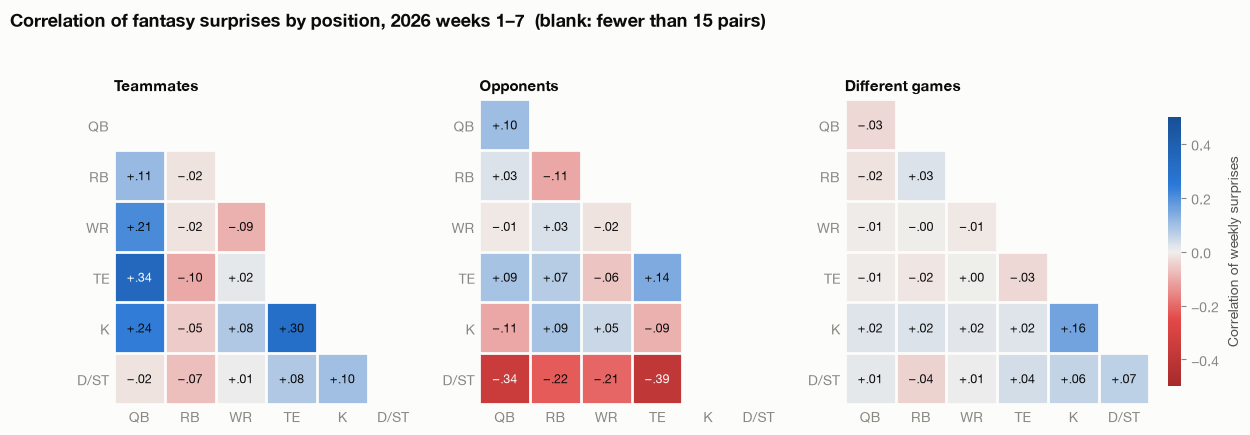

In [7]:
MIN_PAIRS = 15


def pos_label(pos: str) -> str:
    return "D/ST" if pos == "DST" else pos


def corr_grid(c: pd.DataFrame) -> np.ndarray:
    grid = np.full((len(POSITIONS), len(POSITIONS)), np.nan)
    for (r1, r2), row in c.iterrows():
        if row["n"] >= MIN_PAIRS:
            i, j = POSITIONS.index(r2), POSITIONS.index(r1)
            grid[i, j] = row["r"]  # lower triangle
    return grid


def heatmap(ax, grid: np.ndarray, title: str):
    im = ax.imshow(np.ma.masked_invalid(grid), cmap=DIVERGING, vmin=-0.5, vmax=0.5)
    labels = [pos_label(pos) for pos in POSITIONS]
    ax.set_xticks(range(len(POSITIONS)), labels)
    ax.set_yticks(range(len(POSITIONS)), labels)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(POSITIONS)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(POSITIONS)), minor=True)
    ax.grid(which="minor", color=COLORS["surface"], linewidth=2)
    ax.tick_params(which="minor", length=0)
    for i in range(len(POSITIONS)):
        for j in range(len(POSITIONS)):
            if not np.isnan(grid[i, j]):
                v = grid[i, j]
                ink = COLORS["surface"] if abs(v) > 0.3 else COLORS["primary"]
                ax.text(
                    j,
                    i,
                    f"{v:+.2f}".replace("+0", "+").replace("-0", "−"),
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=ink,
                )
    ax.set_title(title, fontsize=11, fontweight="bold")
    return im


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, c) in zip(axes, pos_corr.items(), strict=True):
    im = heatmap(ax, corr_grid(c), name)
cbar = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.015)
cbar.set_label("Correlation of weekly surprises", color=COLORS["secondary"])
cbar.outline.set_visible(False)
fig.suptitle(
    f"Correlation of fantasy surprises by position, {SEASON} weeks 1–{LAST_WEEK}  "
    f"(blank: fewer than {MIN_PAIRS} pairs)",
    x=0.06,
    ha="left",
    fontsize=13,
    fontweight="bold",
)
plt.show()

Teammates and opponents side by side, with 95% intervals.

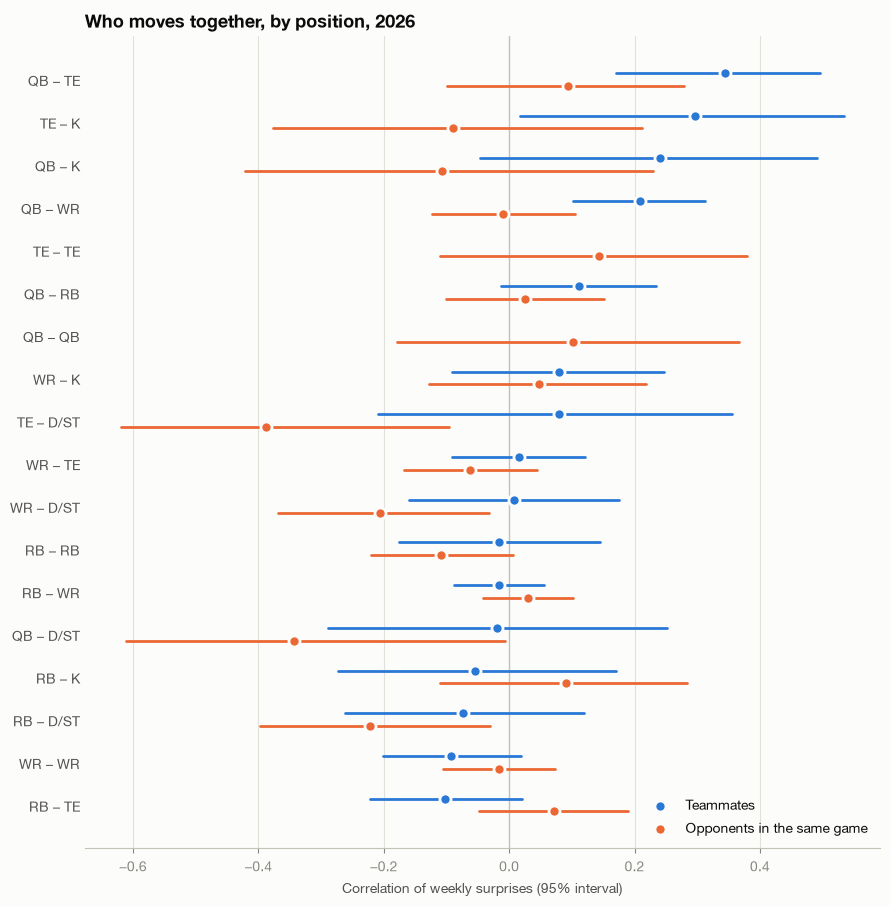

In [8]:
same_g, opp_g = pos_corr["Teammates"], pos_corr["Opponents"]
pairs_shown = [k for k in opp_g.index if opp_g.loc[k, "n"] >= MIN_PAIRS]
pairs_shown.sort(
    key=lambda k: (
        -same_g.loc[k, "r"]
        if k in same_g.index and same_g.loc[k, "n"] >= MIN_PAIRS
        else -opp_g.loc[k, "r"]
    )
)

fig, ax = plt.subplots(figsize=(9, 0.42 * len(pairs_shown) + 1.6))
ax.axvline(0, color=COLORS["axis"], linewidth=1)
y = np.arange(len(pairs_shown))
for c, color, label, dy in [
    (same_g, COLORS["same"], "Teammates", -0.15),
    (opp_g, COLORS["opp"], "Opponents in the same game", 0.15),
]:
    for yi, k in zip(y, pairs_shown, strict=True):
        if k in c.index and c.loc[k, "n"] >= MIN_PAIRS:
            row = c.loc[k]
            ax.plot(
                [row["lo"], row["hi"]],
                [yi + dy] * 2,
                color=color,
                linewidth=2,
                solid_capstyle="round",
            )
            ax.scatter(
                row["r"],
                yi + dy,
                s=64,
                color=color,
                edgecolor=COLORS["surface"],
                linewidth=2,
                zorder=3,
                label=label if yi == 0 else None,
            )
ax.set_yticks(y, [f"{pos_label(a)} – {pos_label(b)}" for a, b in pairs_shown])
ax.invert_yaxis()
ax.tick_params(axis="y", length=0, labelcolor=COLORS["secondary"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlation of weekly surprises (95% interval)")
ax.legend(loc="lower right", frameon=False)
ax.set_title(f"Who moves together, by position, {SEASON}", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 3. The independence check: players in different games

If players in different games are independent, every cell of the "Different games" heatmap
should be 0 up to sampling noise. With *n* pairs, noise alone gives a spread of about
1/√n. A cell more than about 3/√n from 0 suggests a **league-wide weekly effect** (a
high-scoring week for everyone, weather, a kickers' week) that a player's own average can't
remove.

In [9]:
null = pos_corr["Different games"].copy()
null["noise_sd"] = 1 / np.sqrt(null["n"])
null["z"] = null["r"] / null["noise_sd"]
print(
    f"Position pairs: {len(null)}. Mean r = {null['r'].mean():+.3f}, "
    f"largest |r| = {null['r'].abs().max():.2f}"
)
print(f"Cells beyond 3 noise SDs: {(null['z'].abs() > 3).sum()}")
null.loc[null["z"].abs() > 3, ["r", "n", "z"]].round(2)

Position pairs: 21. Mean r = +0.014, largest |r| = 0.16
Cells beyond 3 noise SDs: 0


,,r,n,z
k1,k2,,,


## 4. Exposure: how many correlated pairs do real lineups carry?

For each team-week, count pairs of **starters** (with a nonzero projection) that are in the
same NFL game:
- **Stacks:** teammates on the same fantasy roster.
- **Same-game opponents on one roster:** e.g. a QB and the WR he plays against.
- **Shared with the fantasy opponent:** one player on each side of the matchup, same game.

In [10]:
starters = entries.loc[entries["starter"] & (entries["week"] <= LAST_WEEK)].copy()
starters["opponent"] = [
    OPPONENT.get(tw) for tw in zip(starters["pro_team"], starters["week"], strict=True)
]
starters["active"] = (starters["projected"] > 0) & starters["opponent"].notna()


def relation(a, b) -> str | None:
    # "Teammates", "Opponents" or None (different games, or someone not playing)
    if not (a.active and b.active):
        return None
    if a.pro_team == b.pro_team:
        return "Teammates"
    if a.pro_team == b.opponent:
        return "Opponents"
    return None


lineups = {key: list(df.itertuples()) for key, df in starters.groupby(["week", "team_id"])}
matchups = [m for m in league.matchups if m.away is not None and m.week <= LAST_WEEK]

rows = []
for m in matchups:
    for side, other in [(m.home, m.away), (m.away, m.home)]:
        mine, theirs = lineups[(m.week, side.team_id)], lineups[(m.week, other.team_id)]
        within = [relation(a, b) for i, a in enumerate(mine) for b in mine[i + 1 :]]
        rows.append(
            {
                "week": m.week,
                "team": side.name,
                "stacks": within.count("Teammates"),
                "same_game_opponents": within.count("Opponents"),
                "shared_with_opponent": sum(
                    relation(a, b) is not None for a in mine for b in theirs
                ),
            }
        )
exposure = pd.DataFrame(rows)
by_team = exposure.groupby("team")[["stacks", "same_game_opponents", "shared_with_opponent"]]
exposure_table = by_team.mean().sort_values("stacks", ascending=False)
exposure_table.index = [with_owner(t) for t in exposure_table.index]
print("Average per team-week:")
print(exposure[["stacks", "same_game_opponents", "shared_with_opponent"]].mean().round(2))
exposure_table.round(2)

Average per team-week:
stacks                  1.20
same_game_opponents     1.53
shared_with_opponent    5.77
dtype: float64


,stacks,same_game_opponents,shared_with_opponent
On a Train Back to Boston · Isaac,2.29,1.00,4.86
I didnt hear no bell · Gavriel,1.86,1.57,6.14
Chubland · Moshe,1.43,1.43,4.86
#EATITFROMTHEBACK · Stein,1.29,1.29,5.29
To Infinity and Bijan · Jake,1.29,1.71,5.86
Will Power · Ben,1.14,1.86,5.71
Chase You to the Playoffs · Levitt,0.86,1.29,6.29
Benevolent Commish · Aaron,0.71,2.14,5.14
The Williams Family · Ryan,0.71,1.57,7.43
The Germiphobes · Kinch,0.43,1.43,6.14


## 5. Impact on scores and results

**Model.** Each starter's expected points is his ESPN projection. His spread is his position's
standard deviation of (actual − projected) this season. Two starters in the same NFL game get
the **position-pair correlation** from section 2. Everyone else gets 0, as hypothesized. From
that:

- **Team score SD:** √(Σσᵢ² + 2·Σ ρᵢⱼσᵢσⱼ), with and without the correlation terms.
- **Margin SD:** √(Var A + Var B − 2·Cov(A, B)).
- **Win probability:** P(M > 0) = Φ(E[M] / SD(M)), under both models.

If correlation matters, the correlated model should match how spread out the real results
were, and predict winners better.

In [11]:
played = starters.loc[starters["active"]]
SIGMA = (played["points"] - played["projected"]).groupby(played["position"]).std()
RHO = {
    (rel, g1, g2): row["r"]
    for rel in ["Teammates", "Opponents"]
    for (g1, g2), row in pos_corr[rel].iterrows()
    if row["n"] >= MIN_PAIRS
}
print("SD of (actual - projected) by position:", SIGMA.round(1).to_dict())


def cov(a, b) -> float:
    rel = relation(a, b)
    if rel is None:
        return 0.0
    g1, g2 = sorted([a.position, b.position], key=POSITIONS.index)
    return RHO.get((rel, g1, g2), 0.0) * SIGMA[a.position] * SIGMA[b.position]


def team_var(lineup) -> tuple[float, float]:
    # (variance assuming independence, variance with correlations)
    ind = sum(SIGMA[p.position] ** 2 for p in lineup if p.active)
    pair_cov = sum(cov(a, b) for i, a in enumerate(lineup) for b in lineup[i + 1 :])
    return ind, ind + 2 * pair_cov


rows = []
for m in matchups:
    assert m.away_score is not None
    home, away = lineups[(m.week, m.home.team_id)], lineups[(m.week, m.away.team_id)]
    (vh_ind, vh), (va_ind, va) = team_var(home), team_var(away)
    cross = sum(cov(a, b) for a in home for b in away)
    expected = sum(p.projected for p in home) - sum(p.projected for p in away)
    rows.append(
        {
            "week": m.week,
            "home": m.home.name,
            "away": m.away.name,
            "home_sd_ind": np.sqrt(vh_ind),
            "home_sd": np.sqrt(vh),
            "away_sd_ind": np.sqrt(va_ind),
            "away_sd": np.sqrt(va),
            "expected_margin": expected,
            "margin_sd_ind": np.sqrt(vh_ind + va_ind),
            "margin_sd": np.sqrt(vh + va - 2 * cross),
            "margin": m.home_score - m.away_score,
            "home_win": float(m.home_score > m.away_score),
        }
    )
games = pd.DataFrame(rows)
games["p_ind"] = norm.cdf(games["expected_margin"] / games["margin_sd_ind"])
games["p_corr"] = norm.cdf(games["expected_margin"] / games["margin_sd"])

team_sd = pd.DataFrame(
    {
        "independent": pd.concat([games["home_sd_ind"], games["away_sd_ind"]]),
        "correlated": pd.concat([games["home_sd"], games["away_sd"]]),
    }
)
change = team_sd["correlated"] / team_sd["independent"] - 1
print(f"Team score SD, independent: {team_sd['independent'].mean():.1f}")
print(
    f"Team score SD, correlated:  {team_sd['correlated'].mean():.1f} "
    f"(range {change.min():+.1%} to {change.max():+.1%} per team-week)"
)

SD of (actual - projected) by position: {'DST': 5.8, 'K': 5.9, 'QB': 8.2, 'RB': 7.7, 'TE': 6.4, 'WR': 7.6}
Team score SD, independent: 22.9
Team score SD, correlated:  23.0 (range -3.9% to +3.3% per team-week)


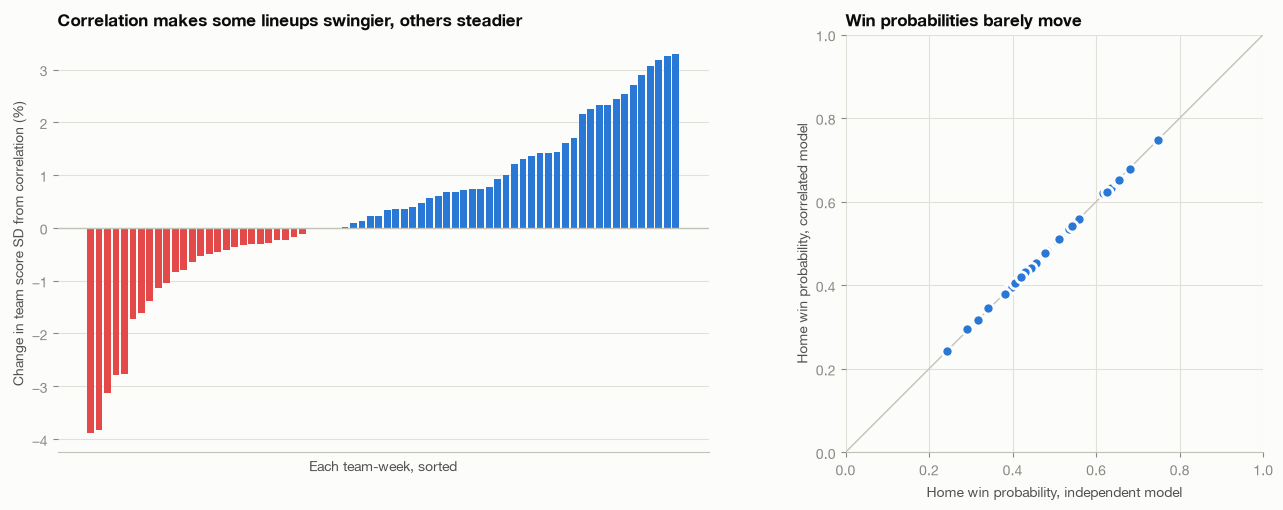

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

ax = axes[0]
pct = 100 * change.sort_values().to_numpy()
ax.bar(
    range(len(pct)), pct, width=0.8, color=[COLORS["same"] if v >= 0 else "#e34948" for v in pct]
)
ax.axhline(0, color=COLORS["axis"], linewidth=1)
ax.set_xticks([])
ax.set_xlabel("Each team-week, sorted")
ax.set_ylabel("Change in team score SD from correlation (%)")
ax.set_title(
    "Correlation makes some lineups swingier, others steadier", fontsize=12, fontweight="bold"
)

ax = axes[1]
lim = [0, 1]
ax.plot(lim, lim, color=COLORS["axis"], linewidth=1)
ax.scatter(
    games["p_ind"],
    games["p_corr"],
    s=64,
    color=COLORS["series"],
    edgecolor=COLORS["surface"],
    linewidth=2,
    zorder=3,
)
ax.set_xlim(*lim)
ax.set_ylim(*lim)
ax.set_aspect("equal")
ax.set_xlabel("Home win probability, independent model")
ax.set_ylabel("Home win probability, correlated model")
ax.set_title("Win probabilities barely move", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

### Does the correlated model fit the real results better?

- **Spread check:** divide each real outcome's miss (actual − expected) by the model's SD. If
  the model has the spread right, those standardized misses have SD 1.
- **Prediction check:** Brier score and log loss of the win probabilities (lower is better).

In [13]:
scored = starters.groupby(["week", "team"])[["points", "projected"]].sum()
team_err = pd.DataFrame(
    {
        "err": [
            scored.loc[(w, t), "points"] - scored.loc[(w, t), "projected"]
            for side in ["home", "away"]
            for w, t in zip(games["week"], games[side], strict=True)
        ],
        "sd_ind": pd.concat([games["home_sd_ind"], games["away_sd_ind"]], ignore_index=True),
        "sd": pd.concat([games["home_sd"], games["away_sd"]], ignore_index=True),
    }
)
margin_err = games["margin"] - games["expected_margin"]
y = games["home_win"]


def brier(p):
    return ((p - y) ** 2).mean()


def log_loss(p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()


fit = pd.DataFrame(
    {
        "Independent": [
            (team_err["err"] / team_err["sd_ind"]).std(),
            (margin_err / games["margin_sd_ind"]).std(),
            brier(games["p_ind"]),
            log_loss(games["p_ind"]),
        ],
        "Correlated": [
            (team_err["err"] / team_err["sd"]).std(),
            (margin_err / games["margin_sd"]).std(),
            brier(games["p_corr"]),
            log_loss(games["p_corr"]),
        ],
    },
    index=[
        "SD of standardized team-score miss (ideal 1)",
        "SD of standardized margin miss (ideal 1)",
        "Brier score",
        "Log loss",
    ],
)
# Do swingier lineups (per the model) actually miss their projection by more?
r_swing = np.corrcoef(team_err["sd"] / team_err["sd_ind"], team_err["err"].abs())[0, 1]
print(
    f"Correlation of (correlated SD / independent SD) with |miss|: {r_swing:+.2f} "
    f"over {len(team_err)} team-weeks"
)
fit.round(3)

Correlation of (correlated SD / independent SD) with |miss|: +0.12 over 70 team-weeks

,Independent,Correlated
SD of standardized team-score miss (ideal 1),0.947,0.941
SD of standardized margin miss (ideal 1),0.860,0.858
Brier score,0.221,0.221
Log loss,0.632,0.632


## 6. A week up close

Every matchup from one week (set `WEEK` to look at another). For each one:
- **Lineups:** both sides' starters with their NFL game, projection and points.
- **Correlated pairs:** every pair of starters in the same NFL game, on the same roster or
  across the matchup, with the correlation the model gives them.
  - **Surprise:** points minus projection. When ρ > 0 the two surprises tend to share a sign.
  - **Margin var:** what the pair adds to the variance of the margin, in points². A pair on one
    roster adds 2ρσσ. A pair split across the matchup removes 2ρσσ, because it moves both
    scores together. The sum over pairs is the gap between the two margin SDs, squared.

In [14]:
WEEK = LAST_WEEK  # any completed week
SLOT_ORDER = ["QB", "RB", "WR", "TE", "FLEX", "DST", "K"]
week_matchups = [m for m in matchups if m.week == WEEK]
week_games = games.loc[games["week"] == WEEK].set_index("home")


def short(p) -> str:
    return f"{p.player} · {p.pro_team}"


def game_label(p) -> str:
    return f"{p.pro_team} v {p.opponent}" if isinstance(p.opponent, str) else f"{p.pro_team} bye"


def by_slot(lineup) -> list:
    return sorted(lineup, key=lambda p: SLOT_ORDER.index(p.slot))


def lineup_table(m):
    # Both lineups side by side, one row per slot (styled, so slots can repeat)
    sides = [by_slot(lineups[(m.week, team.team_id)]) for team in (m.home, m.away)]
    shared_slots = [p.slot for p in sides[0]] == [p.slot for p in sides[1]]
    columns = {}
    if shared_slots:
        columns[("", "slot")] = [p.slot for p in sides[0]]
    for team, rows in zip((m.home, m.away), sides, strict=True):
        name = with_owner(team.name)
        if not shared_slots:
            columns[(name, "slot")] = pd.Series([p.slot for p in rows])
        columns[(name, "player")] = pd.Series(
            [f"{p.player} ({p.position})" if p.slot == "FLEX" else p.player for p in rows]
        )
        columns[(name, "game")] = pd.Series([game_label(p) for p in rows])
        columns[(name, "proj")] = pd.Series([p.projected for p in rows])
        columns[(name, "pts")] = pd.Series([p.points for p in rows])
    table = pd.DataFrame(columns)
    return table.style.hide(axis="index").format(precision=1, na_rep="")


def matchup_pairs(m) -> pd.DataFrame:
    sides = [(team.name, p) for team in (m.home, m.away) for p in lineups[(m.week, team.team_id)]]
    rows = []
    for (side_a, a), (side_b, b) in itertools.combinations(sides, 2):
        rel = relation(a, b)
        if rel is None:
            continue
        c = cov(a, b)
        same_roster = side_a == side_b
        rows.append(
            {
                "player_a": f"{short(a)} ({OWNERS[side_a]})",
                "player_b": f"{short(b)} ({OWNERS[side_b]})",
                "link": ("Same roster" if same_roster else "Across matchup")
                + (", NFL teammates" if rel == "Teammates" else ", NFL opponents"),
                "rho": c / (SIGMA[a.position] * SIGMA[b.position]),
                "surprise_a": a.points - a.projected,
                "surprise_b": b.points - b.projected,
                "margin_var": (2 if same_roster else -2) * c,
            }
        )
    if not rows:
        return pd.DataFrame()
    out = pd.DataFrame(rows)
    return out.sort_values("margin_var", key=abs, ascending=False, ignore_index=True).round(2)


summary_rows = []
for m in week_matchups:
    g = week_games.loc[m.home.name]
    pairs = matchup_pairs(m)
    summary_rows.append(
        {
            "home": with_owner(m.home.name),
            "score": f"{m.home_score:.1f} – {m.away_score:.1f}",
            "away": with_owner(m.away.name),
            "proj_margin": g["expected_margin"],
            "margin": g["margin"],
            "correlated_pairs": len(pairs),
            "margin_sd_ind": g["margin_sd_ind"],
            "margin_sd_corr": g["margin_sd"],
            "home_win_p_ind": g["p_ind"],
            "home_win_p_corr": g["p_corr"],
        }
    )
print(f"Week {WEEK} results")
pd.DataFrame(summary_rows).round(2)

Week 7 results


,home,score,away,proj_margin,margin,correlated_pairs,margin_sd_ind,margin_sd_corr,home_win_p_ind,home_win_p_corr
0,#EATITFROMTHEBACK · Stein,131.8 – 107.4,Benevolent Commish · Aaron,3.39,24.40,13,32.19,32.28,0.54,0.54
1,I didnt hear no bell · Gavriel,107.6 – 135.9,The Williams Family · Ryan,-15.43,-28.28,21,32.47,32.39,0.32,0.32
2,Will Power · Ben,114.7 – 125.4,To Infinity and Bijan · Jake,0.84,-10.72,14,32.49,32.50,0.51,0.51
3,Chase You to the Playoffs · Levitt,111.9 – 143.8,Chubland · Moshe,-1.80,-31.90,12,32.49,32.71,0.48,0.48
4,On a Train Back to Boston · Isaac,58.9 – 117.0,The Germiphobes · Kinch,-22.41,-58.06,8,32.21,32.17,0.24,0.24


### The week's most correlated matchup

The matchup whose correlated pairs add up to the most margin variance (in absolute terms).
The chart shows the correlation the model uses between each pair of starters, home team first.
The lines split the two rosters: the top-left and bottom-right blocks are pairs on one roster (stacks), and the
off-diagonal blocks are pairs across the matchup. Blank cells are pairs in different NFL
games, which the model treats as independent.

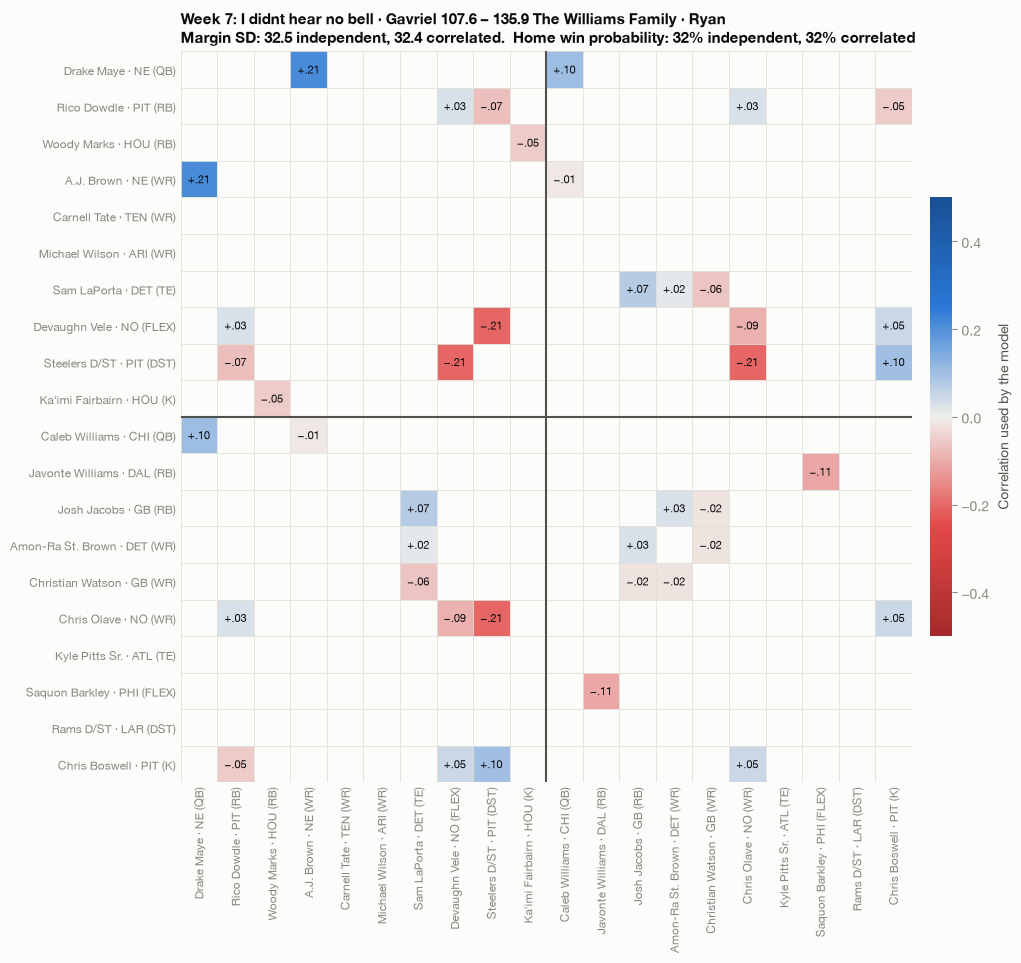

In [15]:
featured = max(
    week_matchups,
    key=lambda m: pairs["margin_var"].abs().sum() if not (pairs := matchup_pairs(m)).empty else 0,
)
players = [
    p for team in (featured.home, featured.away) for p in by_slot(lineups[(WEEK, team.team_id)])
]
n_home = len(lineups[(WEEK, featured.home.team_id)])
grid = np.full((len(players), len(players)), np.nan)
for i, j in itertools.combinations(range(len(players)), 2):
    a, b = players[i], players[j]
    if relation(a, b) is not None:
        grid[i, j] = grid[j, i] = cov(a, b) / (SIGMA[a.position] * SIGMA[b.position])

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(np.ma.masked_invalid(grid), cmap=DIVERGING, vmin=-0.5, vmax=0.5)
labels = [f"{short(p)} ({p.slot})" for p in players]
ax.set_xticks(range(len(players)), labels, rotation=90)
ax.set_yticks(range(len(players)), labels)
ax.tick_params(length=0, labelsize=8.5)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(players)), minor=True)
ax.set_yticks(np.arange(-0.5, len(players)), minor=True)
ax.grid(which="minor", color=COLORS["grid"], linewidth=0.6)
ax.tick_params(which="minor", length=0)
ax.axhline(n_home - 0.5, color=COLORS["secondary"], linewidth=1.5)
ax.axvline(n_home - 0.5, color=COLORS["secondary"], linewidth=1.5)
for i, j in zip(*np.where(~np.isnan(grid)), strict=True):
    v = grid[i, j]
    ink = COLORS["surface"] if abs(v) > 0.3 else COLORS["primary"]
    ax.text(
        j,
        i,
        f"{v:+.2f}".replace("+0", "+").replace("-0", "−"),
        ha="center",
        va="center",
        fontsize=8,
        color=ink,
    )
cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Correlation used by the model", color=COLORS["secondary"])
cbar.outline.set_visible(False)
g = week_games.loc[featured.home.name]
ax.set_title(
    f"Week {WEEK}: {with_owner(featured.home.name)} {featured.home_score:.1f} – "
    f"{featured.away_score:.1f} {with_owner(featured.away.name)}\n"
    f"Margin SD: {g['margin_sd_ind']:.1f} independent, {g['margin_sd']:.1f} correlated.  "
    f"Home win probability: {g['p_ind']:.0%} independent, {g['p_corr']:.0%} correlated",
    fontsize=11,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

### Every matchup that week

In [16]:
for m in week_matchups:
    g = week_games.loc[m.home.name]
    winner = m.winner.name if m.winner else None
    display(
        Markdown(
            f"#### {with_owner(m.home.name)} {m.home_score:.1f} – {m.away_score:.1f} "
            f"{with_owner(m.away.name)}\n"
            f"Winner: **{with_owner(winner) if winner else 'tie'}**. "
            f"Projected margin {g['expected_margin']:+.1f}, actual {g['margin']:+.1f}. "
            f"Margin SD {g['margin_sd_ind']:.1f} independent → {g['margin_sd']:.1f} correlated; "
            f"home win probability {g['p_ind']:.0%} → {g['p_corr']:.0%}."
        )
    )
    display(lineup_table(m))
    pairs = matchup_pairs(m)
    if pairs.empty:
        display(Markdown("_No starters share an NFL game._"))
    else:
        display(pairs)

#### #EATITFROMTHEBACK · Stein 131.8 – 107.4 Benevolent Commish · Aaron
Winner: **#EATITFROMTHEBACK · Stein**. Projected margin +3.4, actual +24.4. Margin SD 32.2 independent → 32.3 correlated; home win probability 54% → 54%.

,player_a,player_b,link,rho,surprise_a,surprise_b,margin_var
0,Tee Higgins · CIN (Stein),Joe Burrow · CIN (Stein),"Same roster, NFL teammates",0.21,12.18,9.57,26.01
1,Isaiah Likely · NYG (Aaron),Dominic Zvada · NYG (Aaron),"Same roster, NFL teammates",0.30,-9.30,-9.38,22.44
2,Kenneth Walker III · KC (Stein),Seahawks D/ST · SEA (Stein),"Same roster, NFL opponents",-0.22,-10.04,4.24,-19.70
3,Tetairoa McMillan · CAR (Stein),Jalen Coker · CAR (Stein),"Same roster, NFL teammates",-0.09,-7.02,-11.17,-10.66
4,Joe Burrow · CIN (Stein),Tyler Loop · BAL (Stein),"Same roster, NFL opponents",-0.11,9.57,-2.10,-10.32
5,Tyler Loop · BAL (Stein),Zay Flowers · BAL (Aaron),"Across matchup, NFL teammates",0.08,-2.10,11.70,-7.17
6,Trey McBride · ARI (Stein),J.K. Dobbins · DEN (Stein),"Same roster, NFL opponents",0.07,9.76,-4.43,7.13
7,Tony Pollard · TEN (Aaron),Titans D/ST · TEN (Aaron),"Same roster, NFL teammates",-0.07,22.08,-7.20,-6.60
8,Nico Collins · HOU (Aaron),Isaiah Likely · NYG (Aaron),"Same roster, NFL opponents",-0.06,-12.41,-9.30,-6.11
9,Tee Higgins · CIN (Stein),Tyler Loop · BAL (Stein),"Same roster, NFL opponents",0.05,12.18,-2.10,4.20


#### I didnt hear no bell · Gavriel 107.6 – 135.9 The Williams Family · Ryan
Winner: **The Williams Family · Ryan**. Projected margin -15.4, actual -28.3. Margin SD 32.5 independent → 32.4 correlated; home win probability 32% → 32%.

,player_a,player_b,link,rho,surprise_a,surprise_b,margin_var
0,A.J. Brown · NE (Gavriel),Drake Maye · NE (Gavriel),"Same roster, NFL teammates",0.21,-7.07,6.85,26.01
1,Devaughn Vele · NO (Gavriel),Steelers D/ST · PIT (Gavriel),"Same roster, NFL opponents",-0.21,5.69,2.56,-18.08
2,Steelers D/ST · PIT (Gavriel),Chris Olave · NO (Ryan),"Across matchup, NFL opponents",-0.21,2.56,-4.00,18.08
3,Drake Maye · NE (Gavriel),Caleb Williams · CHI (Ryan),"Across matchup, NFL opponents",0.10,6.85,4.53,-13.61
4,Saquon Barkley · PHI (Ryan),Javonte Williams · DAL (Ryan),"Same roster, NFL opponents",-0.11,0.20,5.93,-12.86
5,Devaughn Vele · NO (Gavriel),Chris Olave · NO (Ryan),"Across matchup, NFL teammates",-0.09,5.69,-4.00,10.66
6,Sam LaPorta · DET (Gavriel),Josh Jacobs · GB (Ryan),"Across matchup, NFL opponents",0.07,-7.90,6.02,-7.13
7,Steelers D/ST · PIT (Gavriel),Chris Boswell · PIT (Ryan),"Across matchup, NFL teammates",0.10,2.56,0.48,-6.73
8,Rico Dowdle · PIT (Gavriel),Steelers D/ST · PIT (Gavriel),"Same roster, NFL teammates",-0.07,4.58,2.56,-6.60
9,Sam LaPorta · DET (Gavriel),Christian Watson · GB (Ryan),"Across matchup, NFL opponents",-0.06,-7.90,-5.76,6.11


#### Will Power · Ben 114.7 – 125.4 To Infinity and Bijan · Jake
Winner: **To Infinity and Bijan · Jake**. Projected margin +0.8, actual -10.7. Margin SD 32.5 independent → 32.5 correlated; home win probability 51% → 51%.

,player_a,player_b,link,rho,surprise_a,surprise_b,margin_var
0,Kyren Williams · LAR (Ben),Ashton Jeanty · LV (Jake),"Across matchup, NFL opponents",-0.11,-0.48,2.44,12.86
1,Kyren Williams · LAR (Ben),Tyler Higbee · LAR (Ben),"Same roster, NFL teammates",-0.10,-0.48,-3.37,-10.17
2,Jonathan Taylor · IND (Ben),Will Reichard · MIN (Ben),"Same roster, NFL opponents",0.09,4.02,1.54,8.19
3,Will Reichard · MIN (Ben),Jordan Addison · MIN (Jake),"Across matchup, NFL teammates",0.08,1.54,-5.76,-7.17
4,George Pickens · DAL (Jake),Brandon Aubrey · DAL (Jake),"Same roster, NFL teammates",0.08,3.01,5.12,7.17
5,Tyler Higbee · LAR (Ben),Ashton Jeanty · LV (Jake),"Across matchup, NFL opponents",0.07,-3.37,2.44,-7.13
6,RJ Harvey · DEN (Jake),Broncos D/ST · DEN (Jake),"Same roster, NFL teammates",-0.07,3.50,-3.36,-6.60
7,Jameson Williams · DET (Ben),Tucker Kraft · GB (Jake),"Across matchup, NFL opponents",-0.06,14.65,3.16,6.11
8,Jonathan Taylor · IND (Ben),Jordan Addison · MIN (Jake),"Across matchup, NFL opponents",0.03,4.02,-5.76,-3.54
9,Bijan Robinson · ATL (Jake),Brock Purdy · SF (Jake),"Same roster, NFL opponents",0.03,-4.56,-8.41,3.23


#### Chase You to the Playoffs · Levitt 111.9 – 143.8 Chubland · Moshe
Winner: **Chubland · Moshe**. Projected margin -1.8, actual -31.9. Margin SD 32.5 independent → 32.7 correlated; home win probability 48% → 48%.

,player_a,player_b,link,rho,surprise_a,surprise_b,margin_var
0,Bucky Irving · TB (Moshe),Chuba Hubbard · CAR (Moshe),"Same roster, NFL opponents",-0.11,10.69,-5.83,-12.86
1,Derrick Henry · BAL (Levitt),Evan McPherson · CIN (Levitt),"Same roster, NFL opponents",0.09,-11.97,-2.70,8.19
2,Ja'Marr Chase · CIN (Levitt),Evan McPherson · CIN (Levitt),"Same roster, NFL teammates",0.08,-3.15,-2.70,7.17
3,Jaxon Smith-Njigba · SEA (Moshe),Jason Myers · SEA (Moshe),"Same roster, NFL teammates",0.08,10.55,-1.96,7.17
4,Rhamondre Stevenson · NE (Levitt),Colston Loveland · CHI (Moshe),"Across matchup, NFL opponents",0.07,9.85,6.95,-7.13
5,Aaron Jones Sr. · MIN (Levitt),Vikings D/ST · MIN (Moshe),"Across matchup, NFL teammates",-0.07,-7.78,2.87,6.60
6,Jets D/ST · NYJ (Levitt),Braelon Allen · NYJ (Moshe),"Across matchup, NFL teammates",-0.07,-7.16,2.77,6.60
7,Drake London · ATL (Levitt),George Kittle · SF (Levitt),"Same roster, NFL opponents",-0.06,2.11,-3.14,-6.11
8,Xavier Worthy · KC (Moshe),Jason Myers · SEA (Moshe),"Same roster, NFL opponents",0.05,-7.32,-1.96,4.20
9,Ja'Marr Chase · CIN (Levitt),Derrick Henry · BAL (Levitt),"Same roster, NFL opponents",0.03,-3.15,-11.97,3.54


#### On a Train Back to Boston · Isaac 58.9 – 117.0 The Germiphobes · Kinch
Winner: **The Germiphobes · Kinch**. Projected margin -22.4, actual -58.1. Margin SD 32.2 independent → 32.2 correlated; home win probability 24% → 24%.

,player_a,player_b,link,rho,surprise_a,surprise_b,margin_var
0,Matthew Stafford · LAR (Isaac),Brock Bowers · LV (Kinch),"Across matchup, NFL opponents",0.09,-1.08,-4.89,-9.79
1,Christian McCaffrey · SF (Kinch),49ers D/ST · SF (Kinch),"Same roster, NFL teammates",-0.07,-0.28,-3.11,-6.60
2,Dallas Goedert · PHI (Isaac),CeeDee Lamb · DAL (Kinch),"Across matchup, NFL opponents",-0.06,-1.50,6.87,6.11
3,Justin Jefferson · MIN (Isaac),Spencer Shrader · IND (Isaac),"Same roster, NFL opponents",0.05,-8.97,-5.98,4.20
4,Ryan Fitzgerald · CAR (Kinch),Chris Godwin Jr. · TB (Kinch),"Same roster, NFL opponents",0.05,-10.95,-3.91,4.20
5,Kendre Miller · NO (Isaac),Germie Bernard · PIT (Kinch),"Across matchup, NFL opponents",0.03,-4.43,-6.60,-3.54
6,Denzel Boston · CLE (Isaac),Quinshon Judkins · CLE (Kinch),"Across matchup, NFL teammates",-0.02,-5.97,10.99,1.91
7,Texans D/ST · HOU (Isaac),Jaylin Noel · HOU (Isaac),"Same roster, NFL teammates",0.01,-7.17,-6.47,0.68


## 7. How big can it get? Hypothetical stacks

Real lineups carry only a pair or two of correlated starters. To see the effect at its
largest, take a lineup of independent starters and swap in same-game players, using the same
position-pair correlations and position SDs.

In [17]:
LINEUP = ["QB", "RB", "RB", "WR", "WR", "WR", "TE", "RB", "K", "DST"]  # QB, 2 RB, 3 WR, TE, FLEX


def lineup_sd(game_of: dict[int, str]) -> float:
    # game_of: lineup index -> ("A" or "B" side of one NFL game). Others are independent.
    var = sum(SIGMA[p] ** 2 for p in LINEUP)
    for i, j in itertools.combinations(range(len(LINEUP)), 2):
        if i in game_of and j in game_of:
            rel = "Teammates" if game_of[i] == game_of[j] else "Opponents"
            g1, g2 = sorted([LINEUP[i], LINEUP[j]], key=POSITIONS.index)
            var += 2 * RHO.get((rel, g1, g2), 0.0) * SIGMA[LINEUP[i]] * SIGMA[LINEUP[j]]
    return float(np.sqrt(var))


scenarios = {
    "All starters in different games": {},
    "QB + 1 WR": {0: "A", 3: "A"},
    "QB + 2 WR + TE": {0: "A", 3: "A", 4: "A", 6: "A"},
    "QB + 2 WR + TE + K": {0: "A", 3: "A", 4: "A", 6: "A", 8: "A"},
    "QB + WR, plus a WR from their opponent": {0: "A", 3: "A", 4: "B"},
    "QB + 2 WR + TE, D/ST facing them": {0: "A", 3: "A", 4: "A", 6: "A", 9: "B"},
}
base = lineup_sd({})
hypo = pd.DataFrame({"team_score_sd": {name: lineup_sd(g) for name, g in scenarios.items()}})
hypo["vs_independent"] = (hypo["team_score_sd"] / base - 1).map("{:+.1%}".format)
hypo.round(1)

,team_score_sd,vs_independent
All starters in different games,23.0,+0.0%
QB + 1 WR,23.5,+2.4%
QB + 2 WR + TE,24.7,+7.3%
QB + 2 WR + TE + K,25.8,+12.5%
"QB + WR, plus a WR from their opponent",23.5,+2.2%
"QB + 2 WR + TE, D/ST facing them",22.6,-1.6%


In [18]:
# What a swingier lineup does to an underdog's chances, for a few projected deficits
deficits = [5, 10, 20]
opp_sd = base
rows = []
for name in ["All starters in different games", "QB + 2 WR + TE + K"]:
    sd_a = hypo.loc[name, "team_score_sd"]
    rows.append(
        {"lineup": name, **{f"down {d}": norm.cdf(-d / np.hypot(sd_a, opp_sd)) for d in deficits}}
    )
underdog = pd.DataFrame(rows).set_index("lineup")
underdog.map("{:.1%}".format)

,down 5,down 10,down 20
lineup,,,
All starters in different games,43.9%,37.9%,26.9%
QB + 2 WR + TE + K,44.3%,38.6%,28.2%


## Findings (2026, weeks 1–7)

**1. Teammates: yes, through the QB.**
- QB with his TE: **+0.34** (95% interval 0.17 to 0.50). QB with his WRs: **+0.21**
  (0.10 to 0.31). QB with his RBs: +0.11, borderline.
- The kicker rides the passing game too: QB–K +0.24, TE–K +0.30.
- Pass catchers on the same team don't move together. WR–WR is −0.09 and WR–TE +0.02, since
  they split one pool of targets. RB–TE is −0.10.

**2. Opponents: the D/ST signal is strong. The shootout signal is weak.**
- A D/ST against the offense it faces: **−0.21 to −0.39** for QB, RB, WR and TE, each
  interval below 0. This is the clearest cross-team effect.
- Opposing offenses are about 0: QB vs. QB +0.10, WR vs. WR −0.02. Seven weeks show no
  shootout effect.

**3. Different games are independent.** 21 position pairs average +0.014, and none is more
than 3 noise SDs from 0. The largest is kicker–kicker (+0.16, 2.3 SDs), a possible hint of a
league-wide kicking environment some weeks.

**4. In this league's real matchups, correlation barely matters.**
- A lineup averages 1.2 stacked pairs and 1.5 same-game opponent pairs. That moves team-score
  SD by −3.9% to +3.3% around a baseline of about 23 points.
- Win probabilities move by under 1 point. Both models fit the real results equally
  (Brier 0.221 for both).

**5. Even a heavy stack is a second-order effect.** QB + 2 WR + TE + K from one team
raises team-score SD by about 12% (23.0 → 25.8). For a 10-point underdog that moves win
chance from 37.9% to 38.6%. Weekly noise of about 23 points per team dwarfs anything
correlation adds. Stacking makes a lineup a little more boom-or-bust; it doesn't change
expected points.

**Caveats.**
- Seven weeks is a small sample. Cells with ~100 pairs are uncertain by about ±0.2.
- K and D/ST only count in weeks someone rostered them.
- The intervals treat pairs as independent although players repeat, so they're a little
  too narrow.
- The matchup model uses ESPN projections as the mean and one SD per position.
- Re-run later in the season for tighter estimates.